# Reservorio Hidroeléctrico: Entendiendo paso a paso

Dos reservorios en cascada, 12 meses, inflows estocásticos.

## Paso 1: Los datos y la física del sistema

Balance hídrico:
$$V_{t+1,r} = V_{t,r} + I_{t,r}(\xi) - x_{t,r} + \mathbb{1}_{\{r>1\}} \cdot x_{t,r-1}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(42)

T = 12; N = 500; n_res = 2; alpha = 0.10

V_max = np.array([500., 300.])
V_min = np.array([100., 50.])
V_0   = np.array([300., 200.])
x_max = np.array([100., 150.])
mu_I  = np.array([40., 30.])
sigma_I = 0.4
prices = np.array([50 + 20*np.sin(np.pi*t/T) for t in range(T)])

inflow = np.random.lognormal(mean=np.log(mu_I), sigma=sigma_I, size=(N, T, n_res))

print("Parametros del sistema:")
print(f"  Reservorio 1: V in [{V_min[0]}, {V_max[0]}], V0={V_0[0]}, x_max={x_max[0]}")
print(f"  Reservorio 2: V in [{V_min[1]}, {V_max[1]}], V0={V_0[1]}, x_max={x_max[1]}")
print(f"  Inflows medios: {mu_I}, volatilidad={sigma_I}")
print(f"  Inflow empirico R1 (media/mes): {inflow[:,:,0].mean(axis=0).round(1)}")
print(f"  Precios: {prices.round(1)}")

Parametros del sistema:
  Reservorio 1: V in [100.0, 500.0], V0=300.0, x_max=100.0
  Reservorio 2: V in [50.0, 300.0], V0=200.0, x_max=150.0
  Inflows medios: [40. 30.], volatilidad=0.4
  Inflow empirico R1 (media/mes): [42.9 42.7 43.  42.7 43.4 42.3 45.2 43.8 43.8 42.6 43.5 42.9]
  Precios: [50.  55.2 60.  64.1 67.3 69.3 70.  69.3 67.3 64.1 60.  55.2]


## Paso 2: Simular la dinamica

Para decisiones x, simulamos volumenes en todos los escenarios.

In [2]:
def simulate_reservoir(x_flat, inflow, V_0, V_min, V_max):
    T, n_res, N = inflow.shape[1], inflow.shape[2], inflow.shape[0]
    x = x_flat.reshape(T, n_res)
    V = np.zeros((N, T, n_res))
    for t in range(T):
        for r in range(n_res):
            V_prev = V_0[r] if t == 0 else V[:, t-1, r]
            upstream = x[t, r-1] if r > 0 else 0.0
            V[:, t, r] = V_prev + inflow[:, t, r] - x[t, r] + upstream
    L = np.zeros(N)
    for t in range(T):
        for r in range(n_res):
            L = np.maximum(L, V_min[r] - V[:, t, r])
            L = np.maximum(L, V[:, t, r] - V_max[r])
    return V, L

def compute_cvar(L, alpha):
    N = len(L)
    sorted_L = np.sort(L)
    idx = min(int(np.ceil((1 - alpha) * N)) - 1, N - 1)
    eta = sorted_L[max(idx, 0)]
    return eta + (1.0 / alpha) * np.mean(np.maximum(L - eta, 0.0)), eta

# Probar con politica balanceada
x_bal = np.array([[mu_I[r] for r in range(n_res)] for _ in range(T)]).flatten()
V_bal, L_bal = simulate_reservoir(x_bal, inflow, V_0, V_min, V_max)
cvar_bal, _ = compute_cvar(L_bal, alpha)

print("Politica balanceada (x = inflow medio):")
print(f"  Reliability = {100*np.mean(L_bal <= 0):.1f}%")
print(f"  CVaR = {cvar_bal:.2f}")
print(f"  L: min={L_bal.min():.1f}, med={np.median(L_bal):.1f}, max={L_bal.max():.1f}")

Politica balanceada (x = inflow medio):
  Reliability = 0.0%
  CVaR = 494.63
  L: min=308.7, med=406.4, max=544.5


## Paso 3: Trayectorias de volumen

Por que la politica balanceada falla?

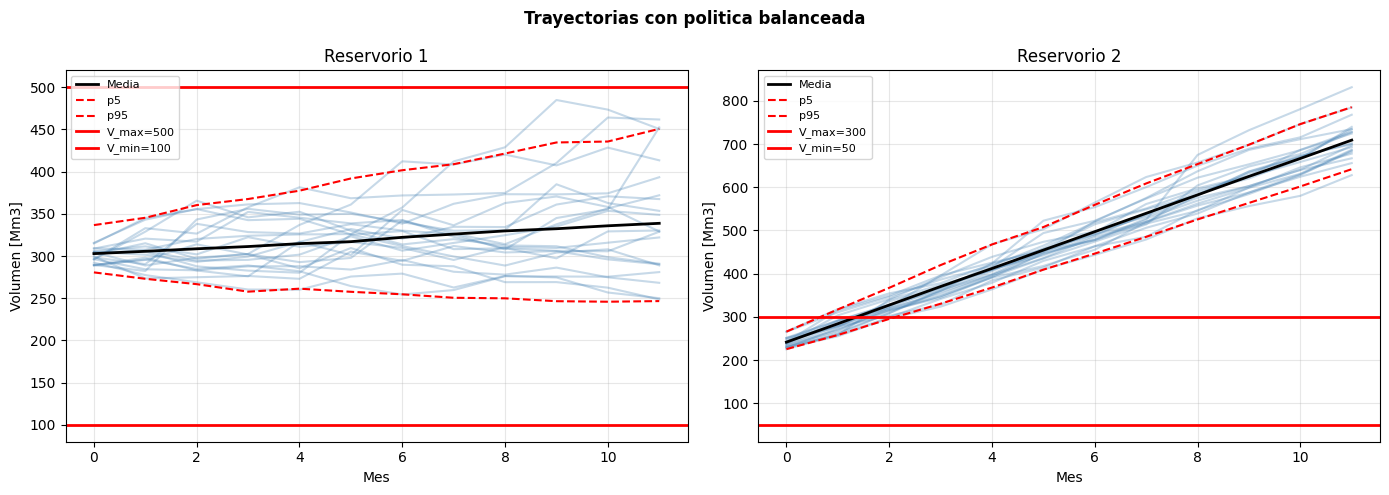

La varianza ACUMULADA crece con t, asi que los bounds se violan mas al final.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for r in range(n_res):
    ax = axes[r]
    for s in range(20):
        ax.plot(range(T), V_bal[s, :, r], alpha=0.3, color='steelblue')
    ax.plot(range(T), V_bal[:,:,r].mean(axis=0), 'k-', lw=2, label='Media')
    ax.plot(range(T), np.percentile(V_bal[:,:,r], 5, axis=0), 'r--', lw=1.5, label='p5')
    ax.plot(range(T), np.percentile(V_bal[:,:,r], 95, axis=0), 'r--', lw=1.5, label='p95')
    ax.axhline(y=V_max[r], color='red', lw=2, label=f'V_max={V_max[r]:.0f}')
    ax.axhline(y=V_min[r], color='red', lw=2, label=f'V_min={V_min[r]:.0f}')
    ax.set_xlabel('Mes'); ax.set_ylabel('Volumen [Mm3]')
    ax.set_title(f'Reservorio {r+1}'); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.suptitle('Trayectorias con politica balanceada', fontweight='bold')
plt.tight_layout(); plt.show()
print("La varianza ACUMULADA crece con t, asi que los bounds se violan mas al final.")

## Paso 4: Explorar politicas extremas

In [3]:
print("Que pasa con distintas politicas fijas?")
print(f"{'Politica':>25} {'Rel':>8} {'Revenue':>10} {'L_max':>8} {'Comentario':>25}")
print("-"*80)

for name, x_flat in [
    ("Minimo (x=0)", np.zeros(T*n_res)),
    ("Bajo (0.5*mu)", np.array([[mu_I[r]*0.5 for r in range(n_res)] for _ in range(T)]).flatten()),
    ("Balanceado (mu)", np.array([[mu_I[r] for r in range(n_res)] for _ in range(T)]).flatten()),
    ("Alto (0.8*xmax)", np.array([[x_max[r]*0.8 for r in range(n_res)] for _ in range(T)]).flatten()),
    ("Maximo (xmax)", np.array([[x_max[r] for r in range(n_res)] for _ in range(T)]).flatten()),
]:
    V, L = simulate_reservoir(x_flat, inflow, V_0, V_min, V_max)
    x = x_flat.reshape(T, n_res)
    rev = sum(prices[t]*x[t,r] for t in range(T) for r in range(n_res))
    rel = 100*np.mean(L <= 0)
    if rel == 0: comm = "Violaciones masivas"
    elif rel < 50: comm = "Muchas violaciones"
    elif rel < 90: comm = "Insuficiente"
    else: comm = "OK"
    print(f"{name:>25} {rel:>7.1f}% ${rev:>9.0f} {L.max():>8.1f} {comm:>25}")

print()
print("Turbinar POCO: volumen sube, viola V_max (se llena)")
print("Turbinar MUCHO: volumen baja, viola V_min (se vacia)")
print("Revenue maximo esta en turbinar al maximo, pero vacia los reservorios")

Que pasa con distintas politicas fijas?
                 Politica      Rel    Revenue    L_max                Comentario
--------------------------------------------------------------------------------
             Minimo (x=0)     0.0% $        0    501.6       Violaciones masivas
            Bajo (0.5*mu)     0.0% $    26317    484.5       Violaciones masivas
          Balanceado (mu)     0.0% $    52634    544.5       Violaciones masivas
          Alto (0.8*xmax)     0.0% $   150383    402.3       Violaciones masivas
            Maximo (xmax)     0.0% $   187979    642.3       Violaciones masivas

Turbinar POCO: volumen sube, viola V_max (se llena)
Turbinar MUCHO: volumen baja, viola V_min (se vacia)
Revenue maximo esta en turbinar al maximo, pero vacia los reservorios


## Paso 5: El Rockafellian para el reservorio

$$\min_x -\text{revenue}(x) \cdot \text{scale} + \frac{\gamma}{2} u^2$$
$$\text{s.a.} \quad \text{CVaR}_\alpha(L(x,\xi)) \leq u, \quad u \geq 0$$

El `scale` es crucial: revenue~$100k vs CVaR~100 Mm3.

In [4]:
def rockafellian_reservoir(x_flat, gamma, revenue_scale, V_min_opt, V_max_opt, alpha_opt):
    x = x_flat.reshape(T, n_res)
    _, L = simulate_reservoir(x_flat, inflow, V_0, V_min_opt, V_max_opt)
    cvar, _ = compute_cvar(L, alpha_opt)
    u = max(cvar, 0.0)
    rev = sum(prices[t]*x[t,r] for t in range(T) for r in range(n_res))
    return -rev * revenue_scale + (gamma / 2.0) * u**2

# Verificar escalas
x_test = np.array([[mu_I[r] for r in range(n_res)] for _ in range(T)]).flatten()
_, L_t = simulate_reservoir(x_test, inflow, V_0, V_min, V_max)
cvar_t, _ = compute_cvar(L_t, alpha)
rev_t = sum(prices[t]*mu_I[r] for t in range(T) for r in range(n_res))

print("Escalas del problema:")
print(f"  Revenue tipico = ${rev_t:.0f}")
print(f"  CVaR tipico = {cvar_t:.2f}")
print(f"  u^2 tipico = {max(cvar_t,0)**2:.0f}")
print(f"  (gamma/2)*u^2 con gamma=1: {0.5*max(cvar_t,0)**2:.0f}")
print()
for scale in [1.0, 0.01, 0.001, 1e-4]:
    ratio = rev_t*scale / (0.5*max(cvar_t,0)**2)
    print(f"  scale={scale}: revenue_term={rev_t*scale:.1f}, penalty_term={0.5*max(cvar_t,0)**2:.1f}, ratio={ratio:.2f}")
print()
print("Queremos ratio ~ 1 para que ambos compitan")

Escalas del problema:
  Revenue tipico = $52634
  CVaR tipico = 494.63
  u^2 tipico = 244663
  (gamma/2)*u^2 con gamma=1: 122332

  scale=1.0: revenue_term=52634.1, penalty_term=122331.5, ratio=0.43
  scale=0.01: revenue_term=526.3, penalty_term=122331.5, ratio=0.00
  scale=0.001: revenue_term=52.6, penalty_term=122331.5, ratio=0.00
  scale=0.0001: revenue_term=5.3, penalty_term=122331.5, ratio=0.00

Queremos ratio ~ 1 para que ambos compitan


## Paso 6: Correr el Rockafellian path

Barremos gamma y observamos u, revenue y reliability.

In [5]:
def run_reservoir_path(V_min_opt, V_max_opt, V_min_check, V_max_check,
                       alpha_opt, revenue_scale, label):
    gamma_values = np.logspace(-1, 4, 15)
    bounds = [(0, x_max[r]) for _ in range(T) for r in range(n_res)]
    x0 = np.array([[mu_I[r]*0.8 for r in range(n_res)] for _ in range(T)]).flatten()

    results = []
    for gamma in gamma_values:
        res = minimize(rockafellian_reservoir, x0,
                       args=(gamma, revenue_scale, V_min_opt, V_max_opt, alpha_opt),
                       method='L-BFGS-B', bounds=bounds,
                       options={'maxiter': 3000, 'ftol': 1e-12})
        x0 = res.x.copy()
        _, L_opt = simulate_reservoir(res.x, inflow, V_0, V_min_opt, V_max_opt)
        cvar_opt, _ = compute_cvar(L_opt, alpha_opt)
        _, L_chk = simulate_reservoir(res.x, inflow, V_0, V_min_check, V_max_check)
        rel_chk = 100*np.mean(L_chk <= 1e-10)
        x_mat = res.x.reshape(T, n_res)
        rev = sum(prices[t]*x_mat[t,r] for t in range(T) for r in range(n_res))
        results.append({'gamma': gamma, 'u': max(cvar_opt, 0), 'revenue': rev,
                        'reliability': rel_chk, 'cvar': cvar_opt, 'x': res.x.copy()})
    return results

print("CASO A: Sin mitigacion (bounds reales, alpha=0.10, scale=1.0)")
print("="*60)
res_A = run_reservoir_path(V_min, V_max, V_min, V_max, 0.10, 1.0, "Sin mitigacion")

print(f"{'gamma':>10} {'u':>10} {'Rel':>8} {'Revenue':>10}")
print("-"*42)
for r in res_A:
    print(f"{r['gamma']:>10.2f} {r['u']:>10.3f} {r['reliability']:>7.1f}% ${r['revenue']:>9.0f}")

CASO A: Sin mitigacion (bounds reales, alpha=0.10, scale=1.0)
     gamma          u      Rel    Revenue
------------------------------------------
      0.10    499.999     0.0% $   183895
      0.23    372.734     0.0% $   176853
      0.52    308.920     0.0% $   166888
      1.18    156.263     0.4% $   140494
      2.68     74.608    32.4% $   125111
      6.11     37.646    76.0% $   117217
     13.89     17.400    87.8% $   112448
     31.62     10.839    92.8% $   110684
     71.97      6.726    95.0% $   109074
    163.79      4.552    97.0% $   107781
    372.76      3.471    97.8% $   106790
    848.34      1.976    98.4% $   104852
   1930.70      0.935    98.4% $   103030
   4393.97      0.516    98.8% $   102193
  10000.00      0.230    99.0% $   101546


## Paso 7: Visualizar Caso A

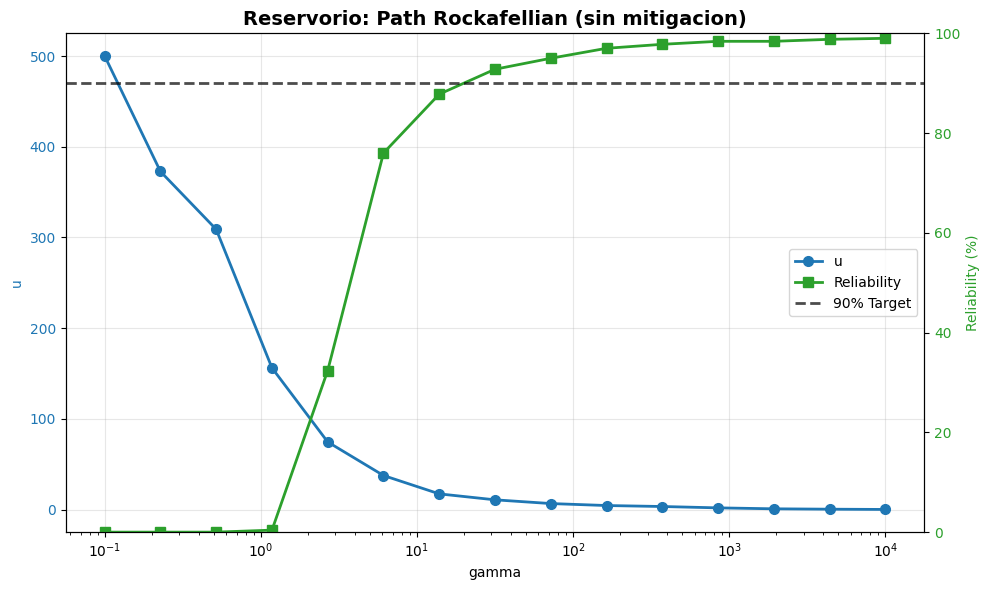

u final = 0.230
Reliability final = 99.0%
CVaR infactible (u*=0.230) PERO CC factible (99.0%)
Esto es el gap de conservadurismo del CVaR


In [6]:
fig, ax1 = plt.subplots(figsize=(10, 6))
gammas = [r['gamma'] for r in res_A]
us = [r['u'] for r in res_A]
rels = [r['reliability'] for r in res_A]

ax1.set_xlabel('gamma'); ax1.set_ylabel('u', color='tab:blue')
ax1.plot(gammas, us, 'o-', lw=2, ms=7, color='tab:blue', label='u')
ax1.tick_params(axis='y', labelcolor='tab:blue'); ax1.set_xscale('log'); ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.set_ylabel('Reliability (%)', color='tab:green')
ax2.plot(gammas, rels, 's-', lw=2, ms=7, color='tab:green', label='Reliability')
ax2.axhline(y=90, color='black', ls='--', lw=2, alpha=0.7, label='90% Target')
ax2.tick_params(axis='y', labelcolor='tab:green'); ax2.set_ylim([0, 100])
plt.title('Reservorio: Path Rockafellian (sin mitigacion)', fontsize=14, fontweight='bold')
l1, lb1 = ax1.get_legend_handles_labels(); l2, lb2 = ax2.get_legend_handles_labels()
ax1.legend(l1+l2, lb1+lb2, loc='center right', fontsize=10)
plt.tight_layout(); plt.show()

print(f"u final = {us[-1]:.3f}")
print(f"Reliability final = {rels[-1]:.1f}%")
if us[-1] > 0.01 and rels[-1] >= 90:
    print(f"CVaR infactible (u*={us[-1]:.3f}) PERO CC factible ({rels[-1]:.1f}%)")
    print("Esto es el gap de conservadurismo del CVaR")

## Paso 8: Caso B - Con mitigacion

1. Safety margins: Delta=10 Mm3
2. alpha-shifting: alpha=0.05
3. Revenue scaling: 0.01

In [7]:
DELTA = 10
print("CASO B: Con mitigacion")
print(f"  Safety margin: Delta = {DELTA}")
print(f"  Optimiza contra: V in [{V_min+DELTA}, {V_max-DELTA}]")
print(f"  Valida contra:   V in [{V_min}, {V_max}]")
print(f"  alpha = 0.05, scale = 0.01")
print("="*60)

res_B = run_reservoir_path(V_min+DELTA, V_max-DELTA, V_min, V_max, 0.05, 0.01, "Mitigado")

print(f"{'gamma':>10} {'u':>10} {'Rel':>8} {'Revenue':>10}")
print("-"*42)
for r in res_B:
    print(f"{r['gamma']:>10.2f} {r['u']:>10.3f} {r['reliability']:>7.1f}% ${r['revenue']:>9.0f}")

CASO B: Con mitigacion
  Safety margin: Delta = 10
  Optimiza contra: V in [[110.  60.], [490. 290.]]
  Valida contra:   V in [[100.  50.], [500. 300.]]
  alpha = 0.05, scale = 0.01
     gamma          u      Rel    Revenue
------------------------------------------
      0.10     24.375    93.2% $   109329
      0.23     12.716    98.6% $   106339
      0.52      9.262    99.0% $   105081
      1.18      6.401    99.0% $   103528
      2.68      3.791    99.2% $   101446
      6.11      1.910    99.8% $    99572
     13.89      1.287    99.8% $    98733
     31.62      1.287    99.8% $    98733
     71.97      1.187   100.0% $    98398
    163.79      1.187   100.0% $    98398
    372.76      1.187   100.0% $    98398
    848.34      1.187   100.0% $    98398
   1930.70      1.187   100.0% $    98398
   4393.97      1.187   100.0% $    98398
  10000.00      1.187   100.0% $    98398


## Paso 9: Comparar ambos casos

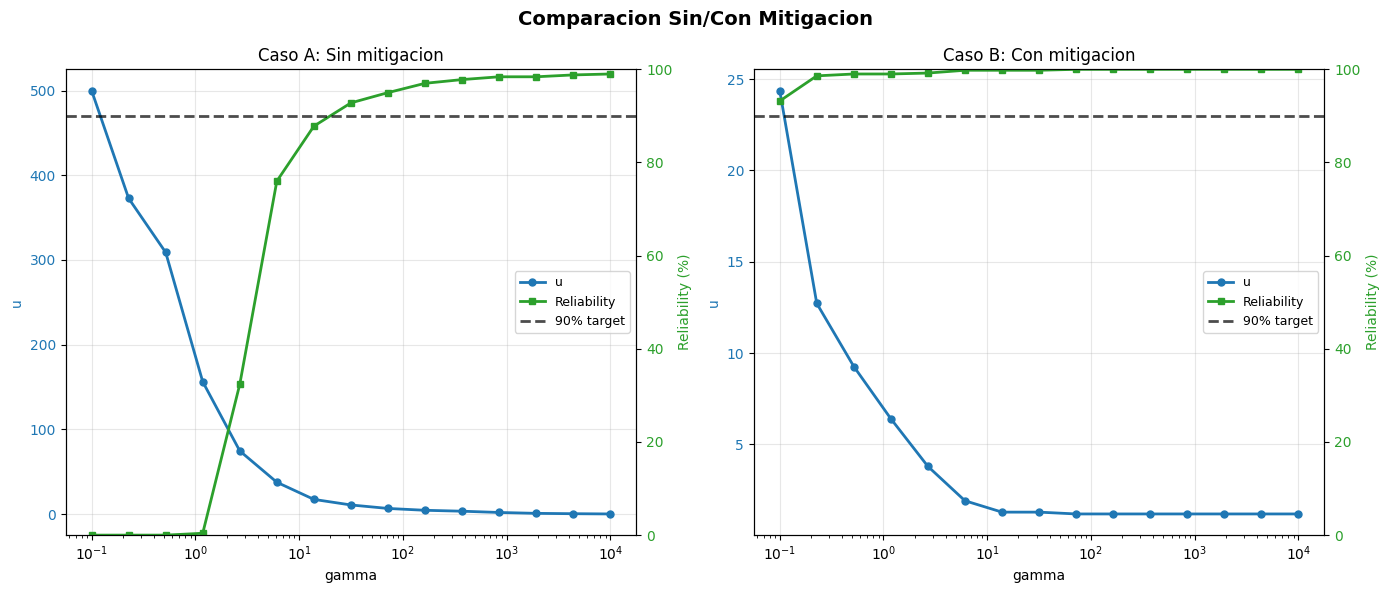

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for col, (results, title) in enumerate([(res_A, "Caso A: Sin mitigacion"), (res_B, "Caso B: Con mitigacion")]):
    ax1 = axes[col]
    gammas = [r['gamma'] for r in results]; us = [r['u'] for r in results]; rels = [r['reliability'] for r in results]
    ax1.set_xlabel('gamma'); ax1.set_ylabel('u', color='tab:blue')
    ax1.plot(gammas, us, 'o-', lw=2, ms=5, color='tab:blue', label='u')
    ax1.tick_params(axis='y', labelcolor='tab:blue'); ax1.set_xscale('log'); ax1.grid(True, alpha=0.3)
    ax2 = ax1.twinx()
    ax2.set_ylabel('Reliability (%)', color='tab:green')
    ax2.plot(gammas, rels, 's-', lw=2, ms=5, color='tab:green', label='Reliability')
    ax2.axhline(y=90, color='black', ls='--', lw=2, alpha=0.7, label='90% target')
    ax2.tick_params(axis='y', labelcolor='tab:green'); ax2.set_ylim([0, 100])
    ax1.set_title(title)
    l1, lb1 = ax1.get_legend_handles_labels(); l2, lb2 = ax2.get_legend_handles_labels()
    ax1.legend(l1+l2, lb1+lb2, fontsize=9, loc='center right')
plt.suptitle('Comparacion Sin/Con Mitigacion', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

## Paso 10: Interpretacion final

In [ ]:
print("="*70)
print("COMPARACION FINAL")
print("="*70)
for label, res in [("A (sin mitigacion)", res_A), ("B (con mitigacion)", res_B)]:
    r = res[-1]
    print(f"\nCaso {label}:")
    print(f"  u final = {r['u']:.4f}")
    print(f"  Reliability = {r['reliability']:.1f}%")
    print(f"  Revenue = ${r['revenue']:.0f}")
    if r['u'] < 0.01:
        print(f"  CVaR factible -> CC factible (conservatividad)")
    else:
        print(f"  CVaR infactible (u*={r['u']:.3f})")
        if r['reliability'] >= 90:
            print(f"  PERO CC si factible ({r['reliability']:.1f}%) -> gap conservadurismo")
        else:
            print(f"  Y CC tampoco factible ({r['reliability']:.1f}%)")

print()
print("="*70)
print("MENSAJES CLAVE")
print("="*70)
print("1. u* mide distancia a factibilidad de la SURROGATE CVaR, no de la CC")
print("2. u*=0 certifica CC factible (por conservatividad)")
print("3. u*>0 NO certifica CC infactible (gap de conservadurismo)")
print("4. La mitigacion crea un colchon entre la surrogate y la CC real")
print("5. AMBAS metricas (u* y reliability) son necesarias")
print("6. La bateria de medidas de riesgo podria cerrar el gap:")
print("   una surrogate menos conservadora daria u* mas informativo")

COMPARACION FINAL

Caso A (sin mitigacion):
  u final = 0.2299
  Reliability = 99.0%
  Revenue = $101546
  CVaR infactible (u*=0.230)
  PERO CC si factible (99.0%) -> gap conservadurismo

Caso B (con mitigacion):
  u final = 1.1871
  Reliability = 100.0%
  Revenue = $98398
  CVaR infactible (u*=1.187)
  PERO CC si factible (100.0%) -> gap conservadurismo

MENSAJES CLAVE
1. u* mide distancia a factibilidad de la SURROGATE CVaR, no de la CC
2. u*=0 certifica CC factible (por conservatividad)
3. u*>0 NO certifica CC infactible (gap de conservadurismo)
4. La mitigacion crea un colchon entre la surrogate y la CC real
5. AMBAS metricas (u* y reliability) son necesarias
6. La bateria de medidas de riesgo podria cerrar el gap:
   una surrogate menos conservadora daria u* mas informativo


---
# PARTE 2: Diseccionando el gap de conservadurismo

Miremos la distribucion de L(x*,xi) para entender por que
el CVaR y la reliability dan mensajes distintos.

## Paso 11: Anatomia de la distribucion de perdida

In [ ]:
# Tomamos la solucion final del Caso A (sin mitigacion)
r_final = res_A[-1]

# Necesitamos recalcular x* - recorremos el path
x0_recon = np.array([[mu_I[r]*0.8 for r in range(n_res)] for _ in range(T)]).flatten()
bounds_recon = [(0, x_max[r]) for _ in range(T) for r in range(n_res)]

for r in res_A:
    res_temp = minimize(rockafellian_reservoir, x0_recon,
                        args=(r['gamma'], 1.0, V_min, V_max, alpha),
                        method='L-BFGS-B', bounds=bounds_recon,
                        options={'maxiter': 3000, 'ftol': 1e-12})
    x0_recon = res_temp.x.copy()

x_star_A = res_temp.x
_, L_star_A = simulate_reservoir(x_star_A, inflow, V_0, V_min, V_max)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de L
ax = axes[0]
ax.hist(L_star_A, bins=50, color='steelblue', alpha=0.7, edgecolor='white')
ax.axvline(x=0, color='red', lw=2, ls='--', label='L=0 (frontera)')
ax.set_xlabel('L (perdida) [Mm3]')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribucion de L(x*,xi) - Caso A')
ax.legend(); ax.grid(True, alpha=0.3)

# Zoom en la zona cercana a 0
ax = axes[1]
L_zoom = L_star_A[(L_star_A > -50) & (L_star_A < 50)]
ax.hist(L_zoom, bins=50, color='steelblue', alpha=0.7, edgecolor='white')
ax.axvline(x=0, color='red', lw=2, ls='--', label='L=0')
ax.set_xlabel('L (perdida) [Mm3]')
ax.set_ylabel('Frecuencia')
ax.set_title('Zoom: zona cercana a L=0')
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

# Estadisticas
cvar_A, eta_A = compute_cvar(L_star_A, alpha)
print(f"Solucion Caso A (gamma={res_A[-1]['gamma']:.0f}):")
print(f"  u* = {max(cvar_A,0):.4f}")
print(f"  Reliability = {100*np.mean(L_star_A<=0):.1f}%")
print(f"\n  Distribucion de L:")
print(f"    L <= 0:       {np.sum(L_star_A<=0):>4d} / {N} = {100*np.mean(L_star_A<=0):.1f}%")
print(f"    0 < L < 1:    {np.sum((L_star_A>0)&(L_star_A<1)):>4d} / {N}")
print(f"    1 <= L < 10:  {np.sum((L_star_A>=1)&(L_star_A<10)):>4d} / {N}")
print(f"    L >= 10:      {np.sum(L_star_A>=10):>4d} / {N}")
print(f"\n  Percentiles: p50={np.percentile(L_star_A,50):.1f}, p90={np.percentile(L_star_A,90):.1f}, p95={np.percentile(L_star_A,95):.1f}, p99={np.percentile(L_star_A,99):.1f}")
print(f"  VaR (eta) = {eta_A:.2f}")
print(f"  CVaR = {cvar_A:.4f}")

---
# PARTE 3: Otras medidas de riesgo

Implementamos mean-semideviation y entropic risk,
luego comparamos las tres medidas en el reservorio.

## Paso 12: Mean-Upper-Semideviation

$$\rho_\lambda(L) = \mathbb{E}[L] + \lambda \sqrt{\mathbb{E}[(L - \mathbb{E}[L])_+^2]}$$

Mas conservadora que CVaR. Calibrada con $\lambda = \Phi^{-1}(1-\alpha)$.

In [ ]:
from scipy.stats import norm

def compute_mean_semidev(L, alpha):
    lam = norm.ppf(1 - alpha)
    mu = np.mean(L)
    dev_pos = np.maximum(L - mu, 0)
    semidev = np.sqrt(np.mean(dev_pos**2))
    return mu + lam * semidev, lam, mu, semidev

def rockafellian_reservoir_semidev(x_flat, gamma, revenue_scale, V_min_opt, V_max_opt, alpha_opt):
    x = x_flat.reshape(T, n_res)
    _, L = simulate_reservoir(x_flat, inflow, V_0, V_min_opt, V_max_opt)
    rho, _, _, _ = compute_mean_semidev(L, alpha_opt)
    u = max(rho, 0.0)
    rev = sum(prices[t]*x[t,r] for t in range(T) for r in range(n_res))
    return -rev * revenue_scale + (gamma / 2.0) * u**2

def run_reservoir_path_semidev(V_min_opt, V_max_opt, V_min_check, V_max_check,
                                alpha_opt, revenue_scale):
    gamma_values = np.logspace(-1, 4, 15)
    bounds = [(0, x_max[r]) for _ in range(T) for r in range(n_res)]
    x0 = np.array([[mu_I[r]*0.8 for r in range(n_res)] for _ in range(T)]).flatten()
    results = []
    for gamma in gamma_values:
        res = minimize(rockafellian_reservoir_semidev, x0,
                       args=(gamma, revenue_scale, V_min_opt, V_max_opt, alpha_opt),
                       method='L-BFGS-B', bounds=bounds,
                       options={'maxiter': 3000, 'ftol': 1e-12})
        x0 = res.x.copy()
        _, L_opt = simulate_reservoir(res.x, inflow, V_0, V_min_opt, V_max_opt)
        _, L_chk = simulate_reservoir(res.x, inflow, V_0, V_min_check, V_max_check)
        rho_sd, _, _, _ = compute_mean_semidev(L_opt, alpha_opt)
        cvar_val, _ = compute_cvar(L_opt, alpha_opt)
        x_mat = res.x.reshape(T, n_res)
        rev = sum(prices[t]*x_mat[t,r] for t in range(T) for r in range(n_res))
        results.append({'gamma': gamma, 'u_semidev': max(rho_sd,0), 'u_cvar': max(cvar_val,0),
                        'revenue': rev, 'reliability': 100*np.mean(L_chk<=1e-10), 'x': res.x.copy()})
    return results

print("Corriendo mean-semideviation para reservorio (sin mitigacion)...")
res_sd_A = run_reservoir_path_semidev(V_min, V_max, V_min, V_max, alpha, 1.0)
print("Listo!")

print(f"\n{'gamma':>10} {'u_sd':>10} {'u_cvar':>10} {'Rel':>8} {'Rev':>10}")
print("-"*52)
for r in res_sd_A:
    print(f"{r['gamma']:>10.2f} {r['u_semidev']:>10.3f} {r['u_cvar']:>10.3f} {r['reliability']:>7.1f}% ${r['revenue']:>9.0f}")

## Paso 13: Entropic Risk

$$\rho_\theta(L) = \frac{1}{\theta} \log \mathbb{E}[e^{\theta L}]$$

Distinta naturaleza: penaliza exponencialmente. No es coherente.

In [ ]:
def compute_entropic(L, theta):
    max_tL = np.max(theta * L)
    log_exp = max_tL + np.log(np.mean(np.exp(theta * L - max_tL)))
    return log_exp / theta

def calibrate_theta(alpha):
    return -np.log(alpha)

def rockafellian_reservoir_entropic(x_flat, gamma, revenue_scale, V_min_opt, V_max_opt, alpha_opt, theta):
    x = x_flat.reshape(T, n_res)
    _, L = simulate_reservoir(x_flat, inflow, V_0, V_min_opt, V_max_opt)
    rho = compute_entropic(L, theta)
    u = max(rho, 0.0)
    rev = sum(prices[t]*x[t,r] for t in range(T) for r in range(n_res))
    return -rev * revenue_scale + (gamma / 2.0) * u**2

def run_reservoir_path_entropic(V_min_opt, V_max_opt, V_min_check, V_max_check,
                                 alpha_opt, revenue_scale):
    theta = calibrate_theta(alpha_opt)
    gamma_values = np.logspace(-1, 4, 15)
    bounds = [(0, x_max[r]) for _ in range(T) for r in range(n_res)]
    x0 = np.array([[mu_I[r]*0.8 for r in range(n_res)] for _ in range(T)]).flatten()
    results = []
    for gamma in gamma_values:
        res = minimize(rockafellian_reservoir_entropic, x0,
                       args=(gamma, revenue_scale, V_min_opt, V_max_opt, alpha_opt, theta),
                       method='L-BFGS-B', bounds=bounds,
                       options={'maxiter': 3000, 'ftol': 1e-12})
        x0 = res.x.copy()
        _, L_opt = simulate_reservoir(res.x, inflow, V_0, V_min_opt, V_max_opt)
        _, L_chk = simulate_reservoir(res.x, inflow, V_0, V_min_check, V_max_check)
        rho_ent = compute_entropic(L_opt, theta)
        cvar_val, _ = compute_cvar(L_opt, alpha_opt)
        rho_sd, _, _, _ = compute_mean_semidev(L_opt, alpha_opt)
        x_mat = res.x.reshape(T, n_res)
        rev = sum(prices[t]*x_mat[t,r] for t in range(T) for r in range(n_res))
        results.append({'gamma': gamma, 'u_entropic': max(rho_ent,0), 'u_cvar': max(cvar_val,0),
                        'u_semidev': max(rho_sd,0), 'revenue': rev,
                        'reliability': 100*np.mean(L_chk<=1e-10), 'x': res.x.copy()})
    return results

print("Corriendo entropic risk para reservorio (sin mitigacion)...")
res_ent_A = run_reservoir_path_entropic(V_min, V_max, V_min, V_max, alpha, 1.0)
print("Listo!")

print(f"\n{'gamma':>10} {'u_ent':>10} {'u_cvar':>10} {'u_sd':>10} {'Rel':>8}")
print("-"*52)
for r in res_ent_A:
    print(f"{r['gamma']:>10.2f} {r['u_entropic']:>10.3f} {r['u_cvar']:>10.3f} {r['u_semidev']:>10.3f} {r['reliability']:>7.1f}%")

## Paso 14: Tabla comparativa — tres medidas en el reservorio

In [ ]:
print("="*80)
print("TABLA COMPARATIVA: RESERVORIO (sin mitigacion)")
print("="*80)
print(f"\n{'Medida optimizada':>20} {'u* propio':>12} {'u* CVaR':>10} {'u* SemiD':>10} {'u* Entr':>10} {'Rel':>7} {'Rev':>10}")
print("-"*82)

# CVaR-optimizada
r = res_A[-1]
# Recalcular x* del CVaR path
x0_r = np.array([[mu_I[rr]*0.8 for rr in range(n_res)] for _ in range(T)]).flatten()
for rr in res_A:
    res_t = minimize(rockafellian_reservoir, x0_r,
                     args=(rr['gamma'], 1.0, V_min, V_max, alpha),
                     method='L-BFGS-B', bounds=bounds_recon,
                     options={'maxiter':3000,'ftol':1e-12})
    x0_r = res_t.x.copy()
_, L_cvar = simulate_reservoir(res_t.x, inflow, V_0, V_min, V_max)
cv, _ = compute_cvar(L_cvar, alpha)
sd, _, _, _ = compute_mean_semidev(L_cvar, alpha)
en = compute_entropic(L_cvar, calibrate_theta(alpha))
rel = 100*np.mean(L_cvar<=0)
rev = r['revenue']
print(f"{'CVaR':>20} {max(cv,0):>12.3f} {max(cv,0):>10.3f} {max(sd,0):>10.3f} {max(en,0):>10.3f} {rel:>6.1f}% ${rev:>9.0f}")

# SemiDev-optimizada
r = res_sd_A[-1]
_, L_sd = simulate_reservoir(r['x'], inflow, V_0, V_min, V_max)
cv2, _ = compute_cvar(L_sd, alpha)
sd2, _, _, _ = compute_mean_semidev(L_sd, alpha)
en2 = compute_entropic(L_sd, calibrate_theta(alpha))
rel2 = 100*np.mean(L_sd<=0)
print(f"{'Mean-SemiDev':>20} {max(sd2,0):>12.3f} {max(cv2,0):>10.3f} {max(sd2,0):>10.3f} {max(en2,0):>10.3f} {rel2:>6.1f}% ${r['revenue']:>9.0f}")

# Entropic-optimizada
r = res_ent_A[-1]
_, L_en = simulate_reservoir(r['x'], inflow, V_0, V_min, V_max)
cv3, _ = compute_cvar(L_en, alpha)
sd3, _, _, _ = compute_mean_semidev(L_en, alpha)
en3 = compute_entropic(L_en, calibrate_theta(alpha))
rel3 = 100*np.mean(L_en<=0)
print(f"{'Entropic':>20} {max(en3,0):>12.3f} {max(cv3,0):>10.3f} {max(sd3,0):>10.3f} {max(en3,0):>10.3f} {rel3:>6.1f}% ${r['revenue']:>9.0f}")

## Paso 15: Paths comparativos

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

gammas = [r['gamma'] for r in res_A]

# u* paths
ax = axes[0]
ax.plot(gammas, [r['u'] for r in res_A], 'o-', lw=2, ms=4, label='CVaR', color='tab:blue')
ax.plot(gammas, [r['u_semidev'] for r in res_sd_A], 's-', lw=2, ms=4, label='Mean-SemiDev', color='tab:orange')
ax.plot(gammas, [r['u_entropic'] for r in res_ent_A], '^-', lw=2, ms=4, label='Entropic', color='tab:green')
ax.set_xscale('log'); ax.set_xlabel('gamma'); ax.set_ylabel('u*')
ax.set_title('u* por medida (cada una optimizando con su propia medida)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# Reliability
ax = axes[1]
ax.plot(gammas, [r['reliability'] for r in res_A], 'o-', lw=2, ms=4, label='CVaR', color='tab:blue')
ax.plot(gammas, [r['reliability'] for r in res_sd_A], 's-', lw=2, ms=4, label='Mean-SemiDev', color='tab:orange')
ax.plot(gammas, [r['reliability'] for r in res_ent_A], '^-', lw=2, ms=4, label='Entropic', color='tab:green')
ax.axhline(y=90, color='black', ls='--', lw=1.5, alpha=0.7, label='90% target')
ax.set_xscale('log'); ax.set_xlabel('gamma'); ax.set_ylabel('Reliability (%)')
ax.set_title('Reliability por medida')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# Revenue
ax = axes[2]
ax.plot(gammas, [r['revenue'] for r in res_A], 'o-', lw=2, ms=4, label='CVaR', color='tab:blue')
ax.plot(gammas, [r['revenue'] for r in res_sd_A], 's-', lw=2, ms=4, label='Mean-SemiDev', color='tab:orange')
ax.plot(gammas, [r['revenue'] for r in res_ent_A], '^-', lw=2, ms=4, label='Entropic', color='tab:green')
ax.set_xscale('log'); ax.set_xlabel('gamma'); ax.set_ylabel('Revenue ($)')
ax.set_title('Revenue por medida')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.suptitle('Reservorio: Comparacion de tres medidas de riesgo', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

## Paso 16: Interpretacion

In [ ]:
print("="*70)
print("INTERPRETACION: BATERIA DE MEDIDAS EN EL RESERVORIO")
print("="*70)

u_cvar = res_A[-1]['u']
u_sd = res_sd_A[-1]['u_semidev']
u_ent = res_ent_A[-1]['u_entropic']
rel_cvar = res_A[-1]['reliability']
rel_sd = res_sd_A[-1]['reliability']
rel_ent = res_ent_A[-1]['reliability']

print(f"  CVaR:        u*={u_cvar:.3f}, rel={rel_cvar:.1f}%")
print(f"  Mean-SemiD:  u*={u_sd:.3f}, rel={rel_sd:.1f}%")
print(f"  Entropic:    u*={u_ent:.3f}, rel={rel_ent:.1f}%")

print()
all_u = [u_cvar, u_sd, u_ent]
all_rel = [rel_cvar, rel_sd, rel_ent]

if all(u < 0.01 for u in all_u):
    print("  TODAS factibles => CC factible (certeza alta)")
elif any(u < 0.01 for u in all_u):
    print("  ALGUNA surrogate factible => CC factible")
    print("  Las otras dan informacion sobre el margen")
else:
    if all(r >= 90 for r in all_rel):
        print("  NINGUNA surrogate factible, PERO CC si factible")
        print("  => Todas las medidas son demasiado conservadoras")
    elif all(r < 90 for r in all_rel):
        print("  NINGUNA surrogate factible Y CC tampoco")
        print("  => Infactibilidad confirmada por multiples medidas")
    else:
        print("  Resultado mixto: depende de la medida")

print()
print("Rango de u*: [{:.3f}, {:.3f}]".format(min(all_u), max(all_u)))
print("Rango de reliability: [{:.1f}%, {:.1f}%]".format(min(all_rel), max(all_rel)))
print()
print("El RANGO entre medidas cuantifica nuestra incertidumbre")
print("sobre el estado real del CC original.")